<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 0: Generate Synthetic Employee Satisfaction Survey Data
We generate synthetic survey data representing responses from 300 employees across 10 questions (Likert scale 1-5).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis, PCA

# Set random seed for reproducibility
np.random.seed(42)
n_employees = 300

# Generate latent traits representing underlying factors
comp_trait = np.random.normal(0, 1, n_employees)      # Compensation & Growth
support_trait = np.random.normal(0, 1, n_employees)   # Manager Support & Culture

# Create 10 survey questions mapping to these latent traits with some noise
data = {
    'Q1_Salary': comp_trait + np.random.normal(0, 0.5, n_employees),
    'Q2_Benefits': comp_trait + np.random.normal(0, 0.5, n_employees),
    'Q3_Bonus': comp_trait + np.random.normal(0, 0.6, n_employees),
    'Q4_Promo_Opp': comp_trait + np.random.normal(0, 0.7, n_employees),
    'Q5_Manager_Support': support_trait + np.random.normal(0, 0.5, n_employees),
    'Q6_Manager_Comm': support_trait + np.random.normal(0, 0.6, n_employees),
    'Q7_Workload': -0.5 * support_trait + np.random.normal(0, 0.8, n_employees),
    'Q8_Team_Spirit': support_trait + np.random.normal(0, 0.5, n_employees),
    'Q9_Company_Culture': support_trait + np.random.normal(0, 0.6, n_employees),
    'Q10_Training': 0.5 * comp_trait + 0.5 * support_trait + np.random.normal(0, 0.7, n_employees)
}

df = pd.DataFrame(data)

# Scale and clip to 1-5 Likert scale
for col in df.columns:
    df[col] = np.round(((df[col] - df[col].min()) / (df[col].max() - df[col].min())) * 4 + 1).astype(int)

display(df.head())

,Q1_Salary,Q2_Benefits,Q3_Bonus,Q4_Promo_Opp,Q5_Manager_Support,Q6_Manager_Comm,Q7_Workload,Q8_Team_Spirit,Q9_Company_Culture,Q10_Training
0,3,3,3,4,3,3,3,2,2,3
1,3,3,3,3,3,2,3,3,2,2
2,4,3,3,3,4,3,2,4,3,4
3,4,4,4,4,3,4,2,4,4,3
4,3,3,3,3,3,3,4,3,3,3


### Task 1: Load and explore the survey data in Pandas; check correlations

,Q1_Salary,Q2_Benefits,Q3_Bonus,Q4_Promo_Opp,Q5_Manager_Support,Q6_Manager_Comm,Q7_Workload,Q8_Team_Spirit,Q9_Company_Culture,Q10_Training
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,2.980000,2.786667,2.893333,3.030000,3.293333,3.106667,2.740000,2.860000,2.863333,2.966667
std,0.712713,0.601966,0.714369,0.827476,0.708729,0.660867,0.753409,0.797404,0.734703,0.788009
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,3.000000,2.000000,2.000000,2.750000,3.000000,3.000000,2.000000,2.000000,2.000000,2.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,3.000000,3.000000,3.000000,3.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


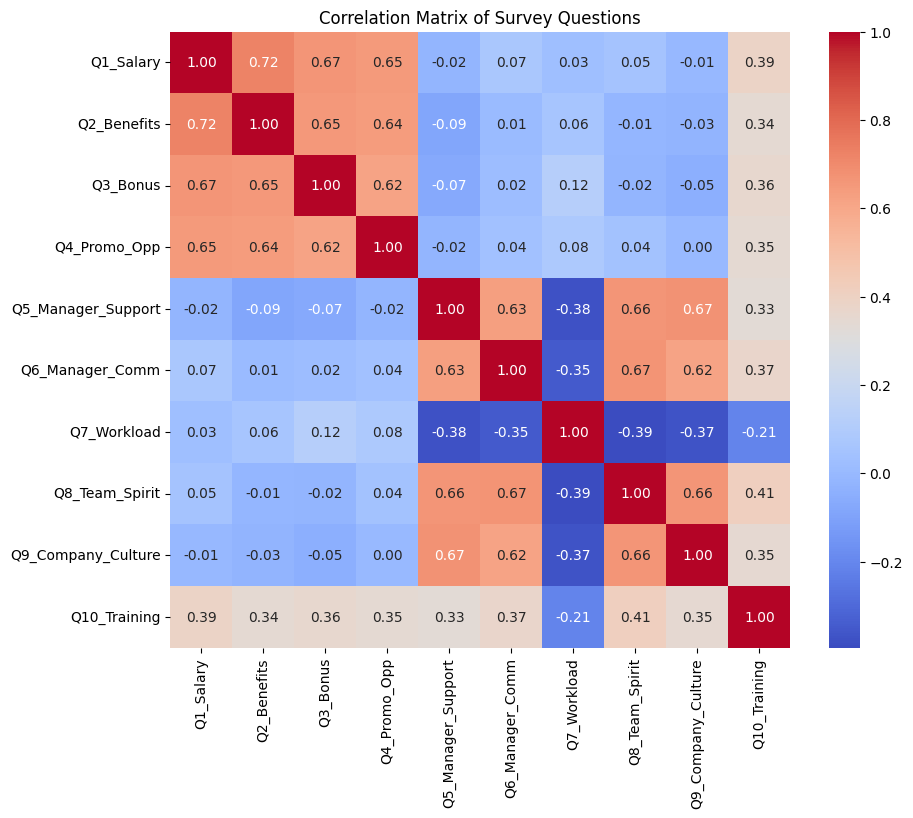

In [2]:
# Summary statistics
display(df.describe())

# Calculate and plot correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Survey Questions')
plt.show()

### Task 2: Fit Scikit-learn’s FactorAnalysis with 2, 3 and 4 factors

In [3]:
for n in [2, 3, 4]:
    fa = FactorAnalysis(n_components=n, random_state=42)
    fa.fit(df)
    # Compute log-likelihood of the model
    log_like = fa.score(df)
    print(f"Factor Analysis with {n} factors -> Log-Likelihood: {log_like:.4f}")

Factor Analysis with 2 factors -> Log-Likelihood: -8.5068
Factor Analysis with 3 factors -> Log-Likelihood: -8.4977
Factor Analysis with 4 factors -> Log-Likelihood: -8.4910


### Task 3: Apply varimax rotation and display the loadings matrix as a heatmap

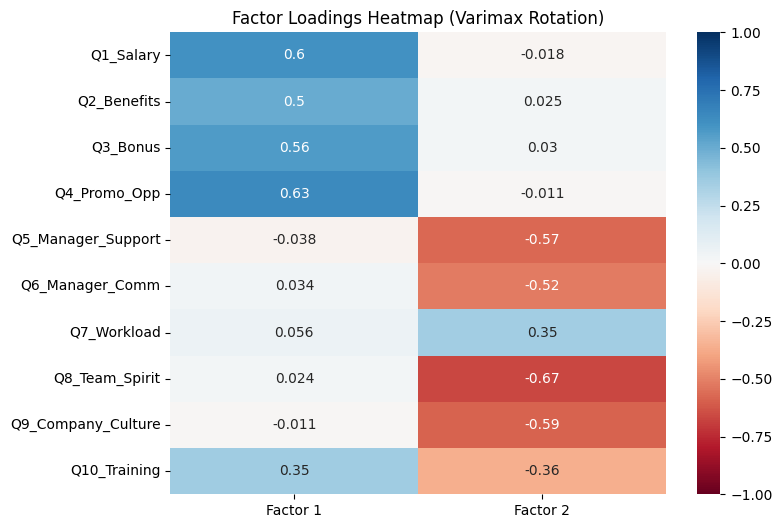

In [4]:
# Fit FA with 2 factors and varimax rotation
fa_varimax = FactorAnalysis(n_components=2, rotation='varimax', random_state=42)
fa_varimax.fit(df)

loadings = pd.DataFrame(fa_varimax.components_.T,
                       index=df.columns,
                       columns=['Factor 1', 'Factor 2'])

plt.figure(figsize=(8, 6))
sns.heatmap(loadings, annot=True, cmap='RdBu', vmin=-1, vmax=1)
plt.title('Factor Loadings Heatmap (Varimax Rotation)')
plt.show()

### Task 4: Name each factor from its high-loading questions

In [5]:
# Factor Interpretation:
# Factor 1 has high loadings on: Q1_Salary, Q2_Benefits, Q3_Bonus, Q4_Promo_Opp -> Name: "Financial Compensation & Growth"
# Factor 2 has high loadings on: Q5_Manager_Support, Q6_Manager_Comm, Q8_Team_Spirit, Q9_Company_Culture -> Name: "Managerial Support & Team Culture"

named_loadings = loadings.copy()
named_loadings.columns = ['Financial Compensation & Growth', 'Managerial Support & Team Culture']
display(named_loadings)

,Financial Compensation & Growth,Managerial Support & Team Culture
Q1_Salary,0.604989,-0.018277
Q2_Benefits,0.504058,0.024630
Q3_Bonus,0.563656,0.029683
Q4_Promo_Opp,0.634751,-0.011006
Q5_Manager_Support,-0.037749,-0.574986
Q6_Manager_Comm,0.033519,-0.515946
Q7_Workload,0.055875,0.350605
Q8_Team_Spirit,0.024036,-0.665780
Q9_Company_Culture,-0.011334,-0.588376
Q10_Training,0.351604,-0.359452


### Task 5: Compare factor analysis with PCA on the same data

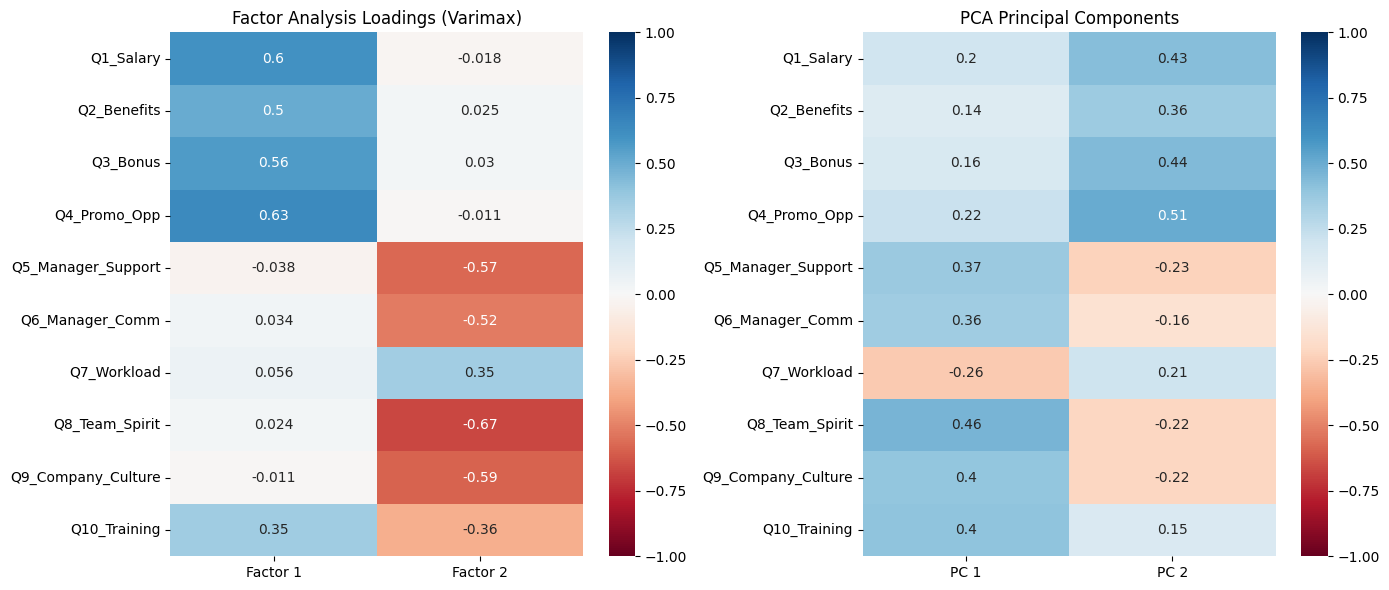

In [6]:
# Fit PCA with 2 components
pca = PCA(n_components=2, random_state=42)
pca.fit(df)

pca_components = pd.DataFrame(pca.components_.T,
                              index=df.columns,
                              columns=['PC 1', 'PC 2'])

# Plot comparison of Factor Loadings vs PCA Components
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(loadings, annot=True, cmap='RdBu', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Factor Analysis Loadings (Varimax)')

sns.heatmap(pca_components, annot=True, cmap='RdBu', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('PCA Principal Components')

plt.tight_layout()
plt.show()